# Lab01 - sprint 1

## Random Variable 02 (n_edge)

### Description

#### 1. О величине

Каждая пластина в датасете — это матрица, где каждая клетка соответствует позиции на сетке:

- 0 — позиция вне пластины (чипа нет)
- 1 — годный чип
- 2 — дефектный чип

Чтобы центр и край были одинаково справедливым парамаетром для всех пластин, радиус нормируется. Центром пластины будет являться точка $(i_c, j_c)$. 
Отношение расстояния от каждого чипа до центра и делим к максимальному расстоянию среди всех настоящих чипов этой пластины будет определять нормированный радиус:

$$r_{ij}=\frac{\sqrt{(i-i_c)^2+(j-j_c)^2}}{\max d}$$

Тогда $r\in[0,1]$: 0 — центр пластины, 1 — самый дальний от центра чип.

n_edge — число дефектных чипов у края, где край — это чипы с $r > 0.8$.

#### 2. О данных 

WM-811K, Wu et al. 2015. 811 457 карт пластин с реального производства. Эксперты разметили около 20% карт по 9 классам: 8 типов паттернов брака и класс none (паттерна нет). 

Для работы данные отфильтрованы:
- класс none — на пластине нет систематического паттерна, дефектные чипы разбросаны случайно. Пластины с паттернами исключены, потому что у каждого паттерна своя причина и своё распределение дефектов;
- dieSize = 516 (самое частое значение) — dieSize это число чипов на пластине, поэтому у всех оставшихся пластин одинаковая сетка и счётчики дефектов можно сравнивать напрямую.

| | |
|---|---|
| Пластин после фильтра | 15881 |
| Лотов | 715 |
| Пластин на лот в среднем | ≈ 22 |
| Чипов на пластине | 516 |
| Чипов в краевой зоне (r > 0.8) | 186 (по площади) |


<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Description (что такое n_edge, данные, почему край особенный, почему величина случайная, какое распределение ожидается) -->

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
import statsmodels.api as sm

# константы
SEED = 42
N_REP = 100        # повторов на размер выборки (состоятельность)
N_SAMPLE = 1000    # размер выборки с возвращением / без
N_MC = 500         # повторов Монте-Карло для sd среднего
B_BOOT = 300       # повторов параметрического бутстрапа
R_CENTER = 0.5     # пороги зон из src/features.py
R_EDGE = 0.8

rng = np.random.default_rng(SEED)

In [2]:
df = pd.read_parquet("../wm811k_features.parquet")
x = df["n_edge"]
print("df.shape =", df.shape)
print("n =", len(x))
print("dieSize =", df["dieSize"].iloc[0], "| уникальных dieSize:", df["dieSize"].nunique())
print("failureType:", df["failureType"].unique().tolist())
print("число лотов =", df["lotName"].nunique())
x.describe()

df.shape = (15881, 11)
n = 15881
dieSize = 516.0 | уникальных dieSize: 1
failureType: ['none']
число лотов = 715


count    15881.000000
mean        41.869719
std          7.803173
min         16.000000
25%         36.000000
50%         41.000000
75%         47.000000
max         79.000000
Name: n_edge, dtype: float64

#### Случайность: разброс внутри лотов

In [3]:
by_lot = df.groupby("lotName")["n_edge"].agg(["count", "min", "max", "mean", "std"])
by_lot[by_lot["count"] >= 10].head(10)

,count,min,max,mean,std
lotName,,,,,
lot42869,23,34,60,45.347826,7.003951
lot42870,25,32,61,45.360000,7.088018
lot42871,21,32,52,44.095238,5.494586
lot42872,23,30,53,42.565217,5.883923
lot42873,21,35,57,45.571429,6.376295
lot42874,24,27,58,45.250000,7.825543
lot42875,23,31,59,44.173913,5.843817
lot42876,23,29,62,44.913043,7.627183
lot42877,25,31,65,43.880000,7.584634


In [4]:
# разложение дисперсии: внутри лотов и между лотами
g = df.groupby("lotName")["n_edge"]
var_within = (g.var(ddof=1).fillna(0) * (g.size() - 1)).sum() / (len(df) - g.ngroups)
var_between = g.mean().var(ddof=1)
icc = var_between / (var_between + var_within)
pd.Series({"дисперсия всей выборки": x.var(ddof=1),
           "внутрилотовая компонента": var_within,
           "межлотовая компонента": var_between,
           "ICC": icc}).round(4)

дисперсия всей выборки      60.8895
внутрилотовая компонента    53.4556
межлотовая компонента        9.7931
ICC                          0.1548
dtype: float64

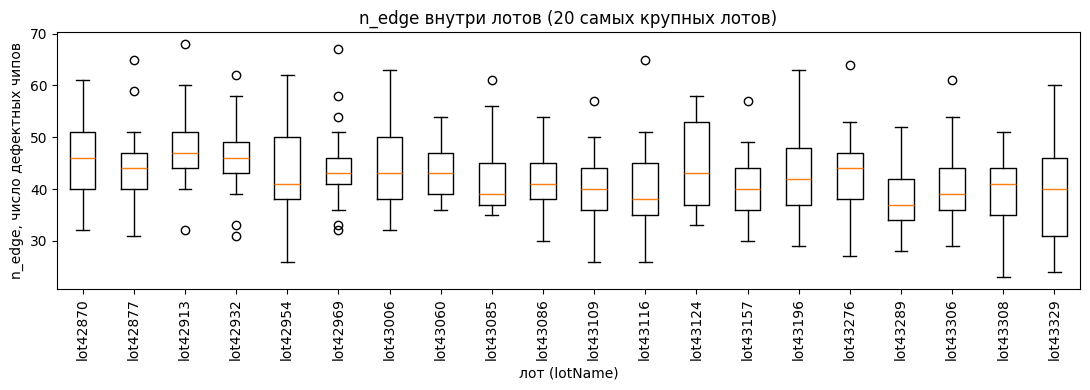

In [5]:
# n_edge по 20 самым крупным лотам
top = df["lotName"].value_counts().head(20).index
data = [df.loc[df["lotName"] == lot, "n_edge"].values for lot in top]
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(data)
ax.set_xticks(range(1, len(top) + 1), top, rotation=90)
ax.set_xlabel("лот (lotName)")
ax.set_ylabel("n_edge, число дефектных чипов")
ax.set_title("n_edge внутри лотов (20 самых крупных лотов)")
plt.tight_layout()
plt.show()

### EDA & Distribution

#### Описательные статистики

In [6]:
desc = pd.Series({
    "n": len(x),
    "среднее": x.mean(),
    "дисперсия (ddof=1)": x.var(ddof=1),
    "ст. отклонение": x.std(ddof=1),
    "медиана": x.median(),
    "q05": x.quantile(0.05),
    "q25": x.quantile(0.25),
    "q50": x.quantile(0.50),
    "q75": x.quantile(0.75),
    "q95": x.quantile(0.95),
    "min": x.min(),
    "max": x.max(),
    "асимметрия": stats.skew(x),
    "эксцесс (избыточный)": stats.kurtosis(x),
    "доля нулей": (x == 0).mean(),
    "индекс дисперсии D = var/mean": x.var(ddof=1) / x.mean(),
})
print("доля нулей n_center:", (df["n_center"] == 0).mean())
desc.round(4)

доля нулей n_center: 0.0


n                                15881.0000
среднее                             41.8697
дисперсия (ddof=1)                  60.8895
ст. отклонение                       7.8032
медиана                             41.0000
q05                                 30.0000
q25                                 36.0000
q50                                 41.0000
q75                                 47.0000
q95                                 55.0000
min                                 16.0000
max                                 79.0000
асимметрия                           0.3144
эксцесс (избыточный)                 0.1074
доля нулей                           0.0000
индекс дисперсии D = var/mean        1.4543
dtype: float64

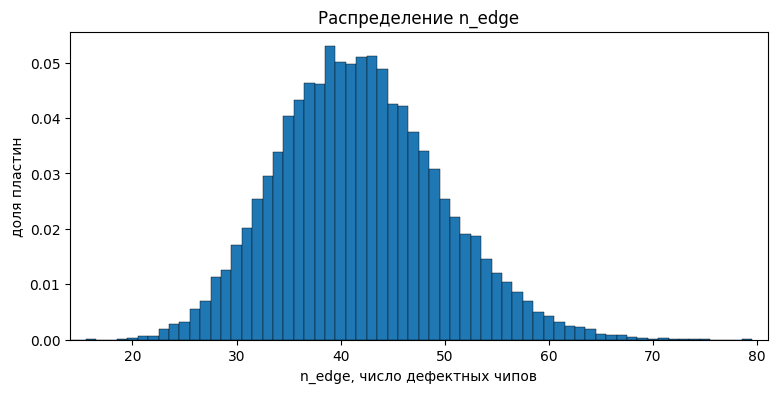

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(x, bins=np.arange(x.max() + 2) - 0.5, density=True, edgecolor="k", linewidth=0.3)
ax.set_xlim(x.min() - 2, x.max() + 2)
ax.set_xlabel("n_edge, число дефектных чипов")
ax.set_ylabel("доля пластин")
ax.set_title("Распределение n_edge")
plt.show()

#### Подгонка распределений

In [8]:
xv = x.to_numpy()
N = len(xv)
m, v = xv.mean(), xv.var(ddof=1)

# Пуассон: ММП lambda = среднее
lam_hat = m
ll_pois = stats.poisson.logpmf(xv, lam_hat).sum()

# ОБР: старт по методу моментов, затем ММП (exp для n, логит для p)
n_mm, p_mm = m**2 / (v - m), m / v

def nll_nb(t, data):
    n_, p_ = np.exp(t[0]), 1 / (1 + np.exp(-t[1]))
    return -stats.nbinom.logpmf(data, n_, p_).sum()

def fit_nbinom(data, start):
    res = optimize.minimize(nll_nb, start, args=(data,), method="Nelder-Mead",
                            options={"xatol": 1e-8, "fatol": 1e-8, "maxiter": 5000})
    return np.exp(res.x[0]), 1 / (1 + np.exp(-res.x[1])), res

start_nb = [np.log(n_mm), np.log(p_mm / (1 - p_mm))]
n_hat, p_hat, res_nb = fit_nbinom(xv, start_nb)
ll_nb = -res_nb.fun

# дискретизированное нормальное: P(k) = Phi(k+0.5) - Phi(k-0.5), ММП
def norm_pmf(k, mu, sd):
    return stats.norm.cdf(k + 0.5, mu, sd) - stats.norm.cdf(k - 0.5, mu, sd)

def fit_dnorm(data):
    res = optimize.minimize(lambda t: -np.log(norm_pmf(data, t[0], np.exp(t[1]))).sum(),
                            [data.mean(), np.log(data.std(ddof=1))], method="Nelder-Mead")
    return res.x[0], np.exp(res.x[1]), res

mu_hat, sd_hat, res_dn = fit_dnorm(xv)
ll_dn = -res_dn.fun

print("сходимость ОБР:", res_nb.success, "| дискр. нормальное:", res_dn.success)
print(f"метод моментов ОБР: n = {n_mm:.4f}, p = {p_mm:.6f}")
print(f"ММП ОБР:            n = {n_hat:.4f}, p = {p_hat:.6f}")
print(f"ОБР: среднее = {stats.nbinom.mean(n_hat, p_hat):.4f}, дисперсия = {stats.nbinom.var(n_hat, p_hat):.4f}")
print(f"Пуассон: lambda = {lam_hat:.4f}")
print(f"дискр. нормальное: mu = {mu_hat:.4f}, sigma = {sd_hat:.4f}")

сходимость ОБР: True | дискр. нормальное: True
метод моментов ОБР: n = 92.1710, p = 0.687634
ММП ОБР:            n = 93.0071, p = 0.689571
ОБР: среднее = 41.8697, дисперсия = 60.7185
Пуассон: lambda = 41.8697
дискр. нормальное: mu = 41.8697, sigma = 7.7976


In [9]:
models = {
    "Пуассон": {"k": 1, "ll": ll_pois, "params": f"lambda={lam_hat:.3f}",
                "pmf": lambda k: stats.poisson.pmf(k, lam_hat)},
    "ОБР": {"k": 2, "ll": ll_nb, "params": f"n={n_hat:.3f}, p={p_hat:.4f}",
            "pmf": lambda k: stats.nbinom.pmf(k, n_hat, p_hat)},
    "дискр. нормальное": {"k": 2, "ll": ll_dn, "params": f"mu={mu_hat:.3f}, sigma={sd_hat:.3f}",
                          "pmf": lambda k: norm_pmf(k, mu_hat, sd_hat)},
}
aic_table = pd.DataFrame({
    name: {"параметры": d["params"], "число параметров": d["k"],
           "logL": d["ll"], "AIC": 2 * d["k"] - 2 * d["ll"]}
    for name, d in models.items()
}).T
aic_table["dAIC"] = aic_table["AIC"].astype(float) - aic_table["AIC"].astype(float).min()
aic_table

,параметры,число параметров,logL,AIC,dAIC
Пуассон,lambda=41.870,1,-55660.854062,111323.708124,1250.440298
ОБР,"n=93.007, p=0.6896",2,-55034.633913,110073.267826,0.000000
дискр. нормальное,"mu=41.870, sigma=7.798",2,-55161.661385,110327.322769,254.054943


In [10]:
# LR-тест Пуассон против ОБР (граничная гипотеза: p-value из chi2(1) делим пополам)
lr = 2 * (ll_nb - ll_pois)
p_lr = 0.5 * stats.chi2.sf(lr, df=1)
print(f"LR = {lr:.4f}, p-value = {p_lr:.3e}")

LR = 1252.4403, p-value = 1.224e-274


In [11]:
# доля нулей: наблюдаемая и по моделям
pd.Series({
    "наблюдаемая": (xv == 0).mean(),
    "Пуассон exp(-lambda)": np.exp(-lam_hat),
    "ОБР p^n": p_hat**n_hat,
    "дискр. нормальное": norm_pmf(0, mu_hat, sd_hat),
})

наблюдаемая             0.000000e+00
Пуассон exp(-lambda)    6.549562e-19
ОБР p^n                 9.697971e-16
дискр. нормальное       2.859985e-08
dtype: float64

#### Графики согласия

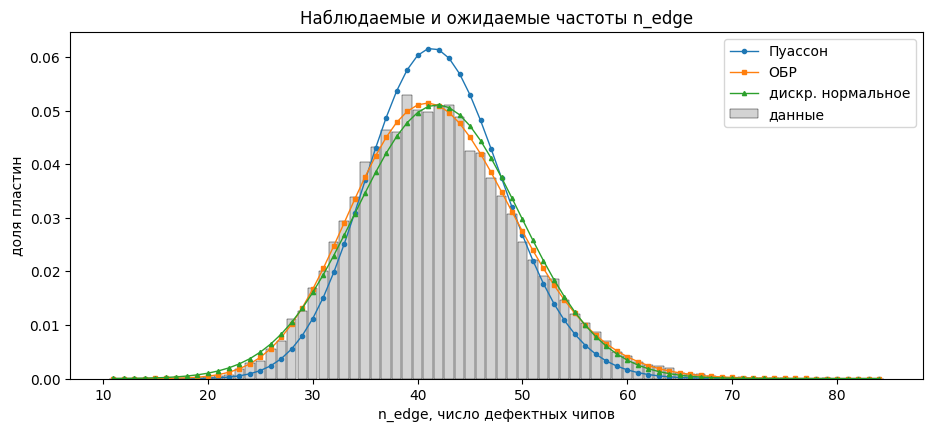

In [12]:
ks = np.arange(xv.min() - 5, xv.max() + 6)
obs_freq = np.array([(xv == k).sum() for k in ks]) / N

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(ks, obs_freq, width=0.9, color="lightgray", edgecolor="k", linewidth=0.3, label="данные")
for (name, d), mk in zip(models.items(), ["o", "s", "^"]):
    ax.plot(ks, d["pmf"](ks), mk + "-", ms=3, lw=1, label=name)
ax.set_xlabel("n_edge, число дефектных чипов")
ax.set_ylabel("доля пластин")
ax.set_title("Наблюдаемые и ожидаемые частоты n_edge")
ax.legend()
plt.show()

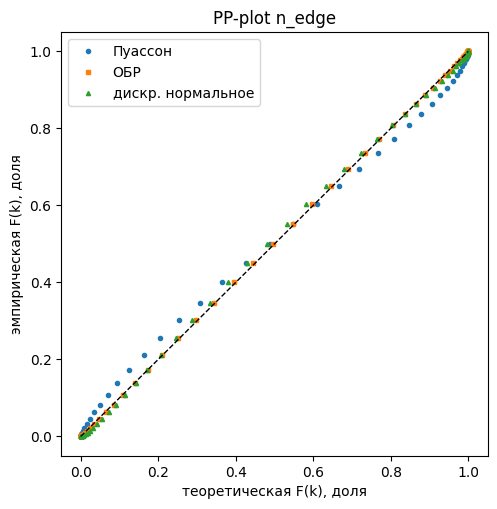

In [13]:
# PP-plot ступенчатых CDF в точках k
emp_cdf = np.array([(xv <= k).mean() for k in ks])
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for (name, d), mk in zip(models.items(), ["o", "s", "^"]):
    ax.plot(np.cumsum(d["pmf"](np.arange(0, ks.max() + 1)))[ks], emp_cdf, mk, ms=3, label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("теоретическая F(k), доля")
ax.set_ylabel("эмпирическая F(k), доля")
ax.set_title("PP-plot n_edge")
ax.legend()
plt.show()

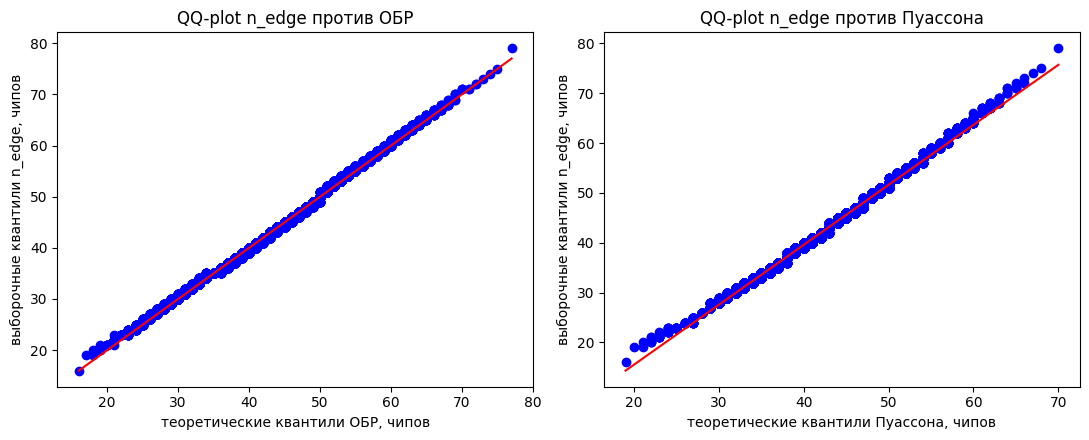

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
stats.probplot(xv, dist=stats.nbinom, sparams=(n_hat, p_hat), plot=axes[0])
axes[0].set_title("QQ-plot n_edge против ОБР")
axes[0].set_xlabel("теоретические квантили ОБР, чипов")
axes[0].set_ylabel("выборочные квантили n_edge, чипов")
stats.probplot(xv, dist=stats.poisson, sparams=(lam_hat,), plot=axes[1])
axes[1].set_title("QQ-plot n_edge против Пуассона")
axes[1].set_xlabel("теоретические квантили Пуассона, чипов")
axes[1].set_ylabel("выборочные квантили n_edge, чипов")
plt.tight_layout()
plt.show()

#### Нормализация

<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Нормализация (зачем нужна, что изменилось) -->

In [15]:
x_bc, lam_bc = stats.boxcox(xv + 1)
print(f"Бокс-Кокс на x+1: lambda = {lam_bc:.4f}")

transforms = {
    "исходные": xv.astype(float),
    "z-score": (xv - xv.mean()) / xv.std(ddof=1),
    "log1p": np.log1p(xv),
    "Бокс-Кокс(x+1)": x_bc,
    "Анскомб 2*sqrt(x+3/8)": 2 * np.sqrt(xv + 3 / 8),
}
pd.DataFrame({name: {"асимметрия": stats.skew(t), "эксцесс (избыточный)": stats.kurtosis(t)}
              for name, t in transforms.items()}).T.round(4)

Бокс-Кокс на x+1: lambda = 0.4152


,асимметрия,эксцесс (избыточный)
исходные,0.3144,0.1074
z-score,0.3144,0.1074
log1p,-0.2303,0.0906
Бокс-Кокс(x+1),-0.0007,-0.0278
Анскомб 2*sqrt(x+3/8),0.0412,-0.0285


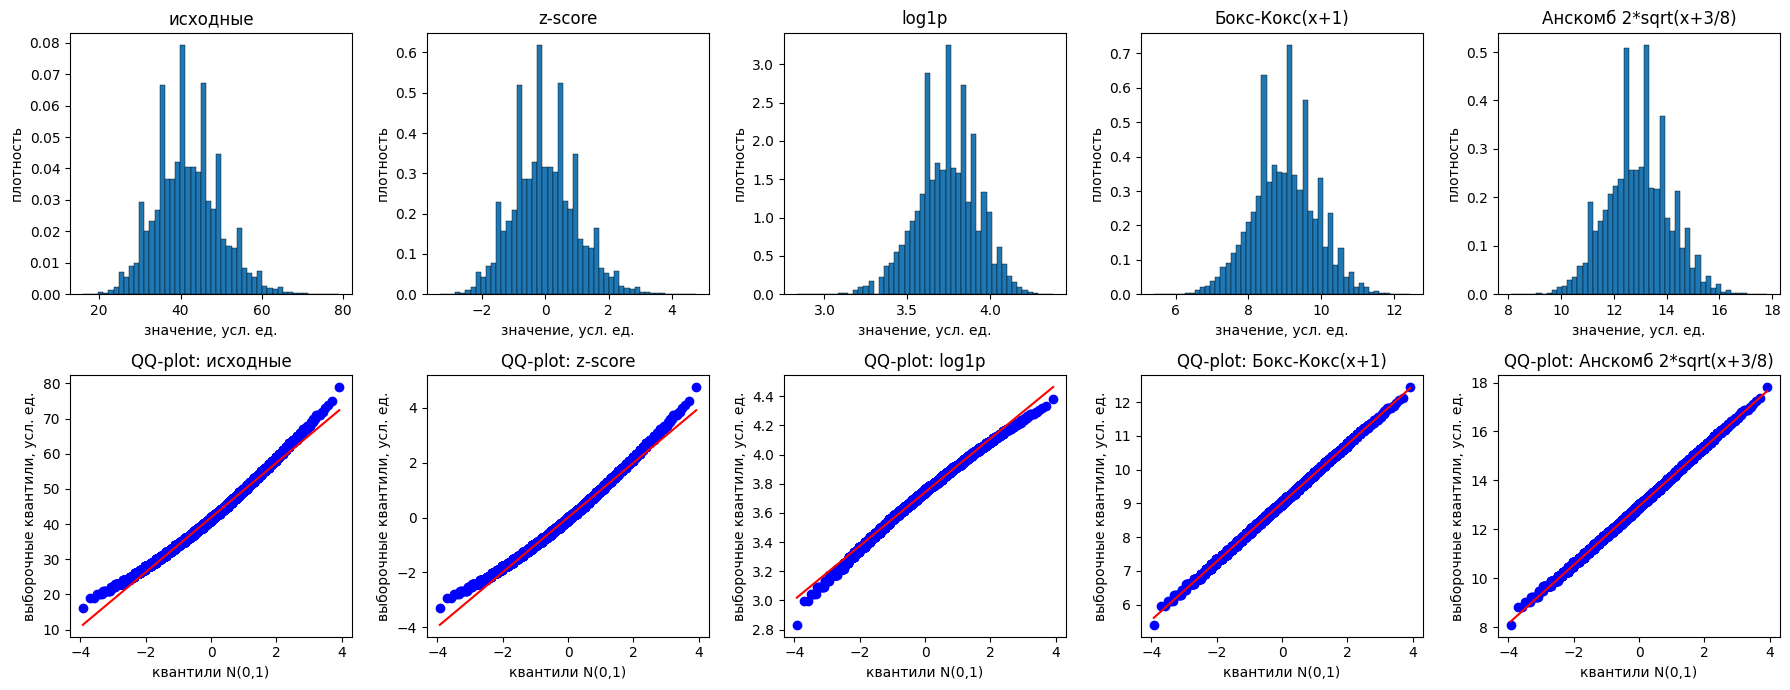

In [16]:
fig, axes = plt.subplots(2, len(transforms), figsize=(18, 7))
for j, (name, t) in enumerate(transforms.items()):
    axes[0, j].hist(t, bins=50, density=True, edgecolor="k", linewidth=0.3)
    axes[0, j].set_title(name)
    axes[0, j].set_xlabel("значение, усл. ед.")
    axes[0, j].set_ylabel("плотность")
    stats.probplot(t, dist="norm", plot=axes[1, j])
    axes[1, j].set_title(f"QQ-plot: {name}")
    axes[1, j].set_xlabel("квантили N(0,1)")
    axes[1, j].set_ylabel("выборочные квантили, усл. ед.")
plt.tight_layout()
plt.show()

#### Математическая база

<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Математическая база (PMF, параметры, моменты, условия возникновения, литература) -->

### Independence & Estimations

#### Состоятельность оценок

<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Состоятельность оценок -->

In [17]:
# выборки с возвращением из всей совокупности, N_REP повторов на каждый размер
sizes = np.unique(np.logspace(1, np.log10(N), 15).astype(int))
true_vals = {"среднее": xv.mean(), "дисперсия": xv.var(ddof=1), "медиана": np.median(xv)}

rows = []
for n in sizes:
    est = np.array([[s.mean(), s.var(ddof=1), np.median(s)]
                    for s in (rng.choice(xv, n, replace=True) for _ in range(N_REP))])
    for j, name in enumerate(true_vals):
        q05, q50, q95 = np.quantile(est[:, j], [0.05, 0.5, 0.95])
        rows.append({"n": n, "оценка": name, "q05": q05, "медиана": q50, "q95": q95})
cons = pd.DataFrame(rows)
cons["ширина 5-95%"] = cons["q95"] - cons["q05"]
cons.pivot(index="n", columns="оценка", values="ширина 5-95%").round(3)

оценка,дисперсия,медиана,среднее
n,,,
10,80.525,10.050,7.630
16,70.078,8.500,6.566
28,55.469,6.025,4.895
48,42.583,4.550,4.223
82,29.627,3.500,3.204
139,23.498,3.000,2.262
235,16.760,3.000,1.709
398,13.925,1.000,1.276
674,10.225,1.000,0.983


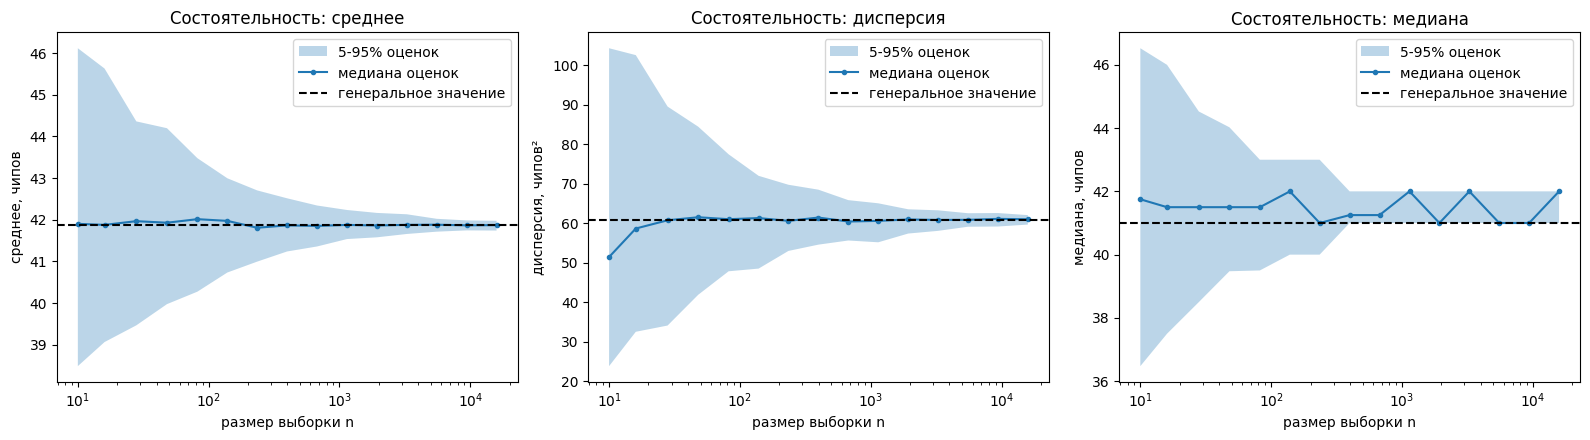

In [18]:
units = {"среднее": "чипов", "дисперсия": "чипов²", "медиана": "чипов"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, true_vals):
    c = cons[cons["оценка"] == name]
    ax.fill_between(c["n"], c["q05"], c["q95"], alpha=0.3, label="5-95% оценок")
    ax.semilogx(c["n"], c["медиана"], "o-", ms=3, label="медиана оценок")
    ax.axhline(true_vals[name], color="k", ls="--", label="генеральное значение")
    ax.set_xlabel("размер выборки n")
    ax.set_ylabel(f"{name}, {units[name]}")
    ax.set_title(f"Состоятельность: {name}")
    ax.legend()
plt.tight_layout()
plt.show()

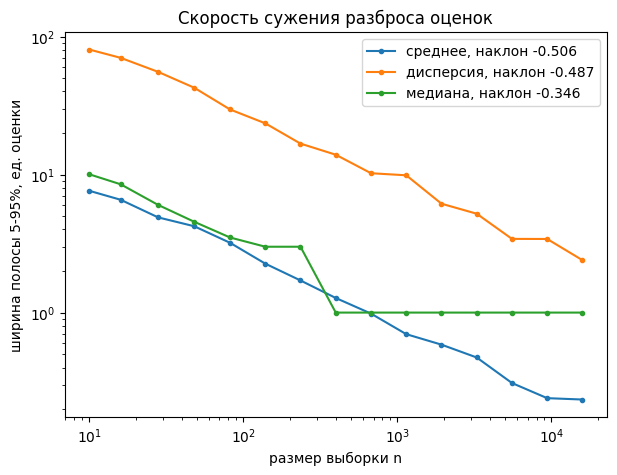

среднее     -0.5058
дисперсия   -0.4869
медиана     -0.3456
Name: наклон, dtype: float64

In [19]:
# ширина полосы 5-95% против n в log-log, наклон по np.polyfit
fig, ax = plt.subplots(figsize=(7, 5))
slopes = {}
for name in true_vals:
    c = cons[(cons["оценка"] == name) & (cons["ширина 5-95%"] > 0)]
    slopes[name] = np.polyfit(np.log10(c["n"]), np.log10(c["ширина 5-95%"]), 1)[0]
    ax.loglog(c["n"], c["ширина 5-95%"], "o-", ms=3, label=f"{name}, наклон {slopes[name]:.3f}")
ax.set_xlabel("размер выборки n")
ax.set_ylabel("ширина полосы 5-95%, ед. оценки")
ax.set_title("Скорость сужения разброса оценок")
ax.legend()
plt.show()
pd.Series(slopes, name="наклон").round(4)

#### Выборки с возвращением и без

<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Выборки с возвращением и без -->

In [20]:
s_with = x.sample(N_SAMPLE, replace=True, random_state=SEED)
s_without = x.sample(N_SAMPLE, replace=False, random_state=SEED)

def summary(s):
    return pd.Series({"n": len(s), "среднее": s.mean(), "дисперсия": s.var(ddof=1),
                      "q05": s.quantile(0.05), "q25": s.quantile(0.25), "медиана": s.median(),
                      "q75": s.quantile(0.75), "q95": s.quantile(0.95)})

pd.DataFrame({"генеральная": summary(x), "с возвращением": summary(s_with),
              "без возвращения": summary(s_without)}).round(3)

,генеральная,с возвращением,без возвращения
n,15881.00,1000.000,1000.000
среднее,41.87,42.244,41.986
дисперсия,60.89,63.490,56.680
q05,30.00,30.000,30.000
q25,36.00,37.000,37.000
медиана,41.00,42.000,42.000
q75,47.00,47.000,47.000
q95,55.00,56.000,56.000


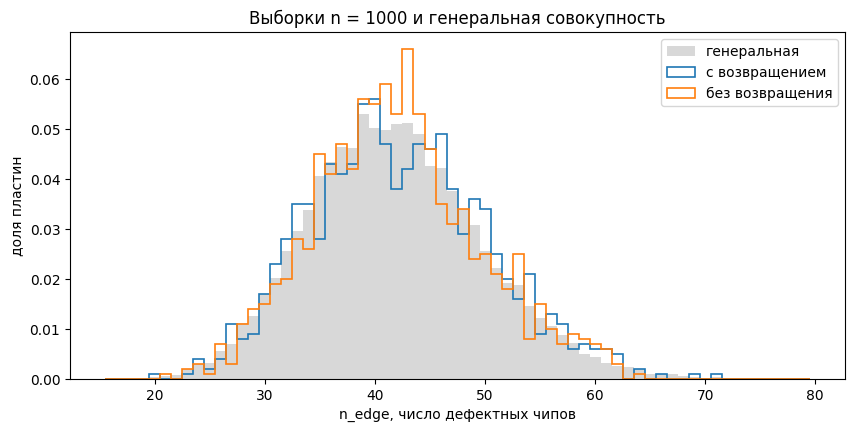

In [21]:
bins = np.arange(x.min(), x.max() + 2) - 0.5
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(x, bins=bins, density=True, histtype="stepfilled", alpha=0.3, color="gray", label="генеральная")
ax.hist(s_with, bins=bins, density=True, histtype="step", lw=1.2, label="с возвращением")
ax.hist(s_without, bins=bins, density=True, histtype="step", lw=1.2, label="без возвращения")
ax.set_xlabel("n_edge, число дефектных чипов")
ax.set_ylabel("доля пластин")
ax.set_title(f"Выборки n = {N_SAMPLE} и генеральная совокупность")
ax.legend()
plt.show()

In [22]:
# группы по децилям генеральной совокупности (группы 0/1/2/3+ не подходят: min(n_edge) > 0)
edges = np.unique(np.quantile(x, np.linspace(0, 1, 11)))
edges[0], edges[-1] = -np.inf, np.inf
grp = lambda s: pd.cut(s, edges)

# без возвращения: выборка против дополнения, chi2 однородности
complement = x.drop(s_without.index)
tab = pd.crosstab(np.r_[np.zeros(len(s_without)), np.ones(len(complement))],
                  np.r_[grp(s_without).astype(str), grp(complement).astype(str)])
chi2_h, p_h, dof_h, E_h = stats.chi2_contingency(tab)
print(f"без возвращения vs дополнение: chi2 = {chi2_h:.3f}, df = {dof_h}, p = {p_h:.4f}, min E = {E_h.min():.1f}")

# с возвращением: chi2 согласия с долями генеральной совокупности
p_pop = grp(x).value_counts(normalize=True).sort_index()
o_w = grp(s_with).value_counts().sort_index()
chi2_w, p_w = stats.chisquare(o_w.values, p_pop.values * len(s_with))
print(f"с возвращением vs генеральная: chi2 = {chi2_w:.3f}, df = {len(o_w) - 1}, p = {p_w:.4f}")

for name, s, ref in [("с возвращением vs генеральная", s_with, x),
                     ("без возвращения vs дополнение", s_without, complement)]:
    r = stats.ks_2samp(s, ref)
    print(f"KS {name}: D = {r.statistic:.4f}, p = {r.pvalue:.4f}")

без возвращения vs дополнение: chi2 = 8.737, df = 9, p = 0.4619, min E = 71.5
с возвращением vs генеральная: chi2 = 10.599, df = 9, p = 0.3042
KS с возвращением vs генеральная: D = 0.0336, p = 0.2334
KS без возвращения vs дополнение: D = 0.0243, p = 0.6283


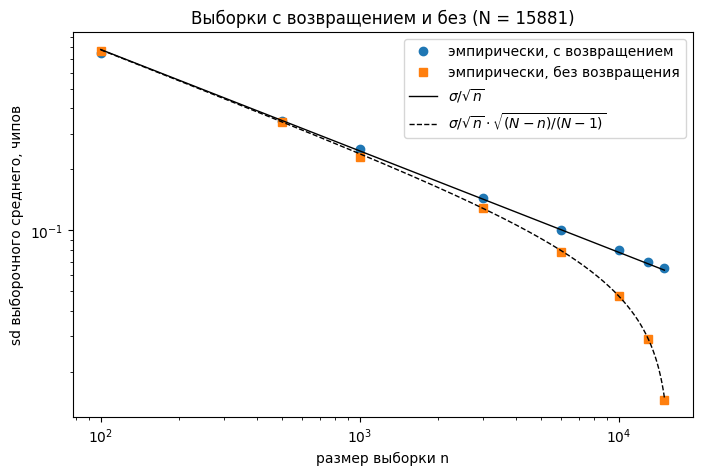

,n,n/N,sd с возвр.,sd без возвр.,теория sigma/sqrt(n),теория с FPC
0,100,0.0063,0.7505,0.7709,0.7803,0.7779
1,500,0.0315,0.3447,0.3443,0.3490,0.3434
2,1000,0.0630,0.2535,0.2294,0.2468,0.2389
3,3000,0.1889,0.1438,0.1288,0.1425,0.1283
4,6000,0.3778,0.1009,0.0785,0.1007,0.0795
5,10000,0.6297,0.0799,0.0476,0.0780,0.0475
6,13000,0.8186,0.0699,0.0291,0.0684,0.0291
7,15000,0.9445,0.0654,0.0147,0.0637,0.0150


In [23]:
# Монте-Карло: sd выборочного среднего с возвращением и без против теории
sigma = xv.std(ddof=0)
n_grid = np.array([100, 500, 1000, 3000, 6000, 10000, 13000, 15000])
mc = []
for n in n_grid:
    m_with = [rng.choice(xv, n, replace=True).mean() for _ in range(N_MC)]
    m_without = [rng.choice(xv, n, replace=False).mean() for _ in range(N_MC)]
    mc.append({"n": n, "n/N": n / N, "sd с возвр.": np.std(m_with, ddof=1),
               "sd без возвр.": np.std(m_without, ddof=1),
               "теория sigma/sqrt(n)": sigma / np.sqrt(n),
               "теория с FPC": sigma / np.sqrt(n) * np.sqrt((N - n) / (N - 1))})
mc = pd.DataFrame(mc)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(mc["n"], mc["sd с возвр."], "o", label="эмпирически, с возвращением")
ax.loglog(mc["n"], mc["sd без возвр."], "s", label="эмпирически, без возвращения")
nn = np.linspace(n_grid.min(), n_grid.max(), 400)
ax.loglog(nn, sigma / np.sqrt(nn), "k-", lw=1, label=r"$\sigma/\sqrt{n}$")
ax.loglog(nn, sigma / np.sqrt(nn) * np.sqrt((N - nn) / (N - 1)), "k--", lw=1,
          label=r"$\sigma/\sqrt{n}\cdot\sqrt{(N-n)/(N-1)}$")
ax.set_xlabel("размер выборки n")
ax.set_ylabel("sd выборочного среднего, чипов")
ax.set_title(f"Выборки с возвращением и без (N = {N})")
ax.legend()
plt.show()
mc.round(4)

#### Проверка гипотез

<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Гипотезы (H0, H1, статистика, p-value, уровень значимости, вывод) -->

In [24]:
# лучшая модель по AIC; chi2 согласия с объединением хвостов (все E >= 5)
best = aic_table["AIC"].astype(float).idxmin()
print("модель для chi2:", best)

def bin_expected(pmf, n_obs, kmax):
    """Ожидаемые по k=0..kmax (последний бин: >= kmax), объединение соседних до E >= 5."""
    k = np.arange(kmax + 1)
    p = pmf(k[:-1])
    probs = np.append(p, 1 - p.sum())
    E = n_obs * probs
    groups, cur, acc = [], [], 0.0
    for i, e in enumerate(E):
        cur.append(i)
        acc += e
        if acc >= 5:
            groups.append(cur)
            cur, acc = [], 0.0
    if cur:
        groups[-1] += cur
    return groups, np.array([E[g].sum() for g in groups])

def chi2_gof(data, pmf, n_params):
    kmax = int(data.max()) + 1
    groups, E = bin_expected(pmf, len(data), kmax)
    counts = np.bincount(np.minimum(data, kmax), minlength=kmax + 1)
    O = np.array([counts[g].sum() for g in groups])
    stat, p = stats.chisquare(O, E, ddof=n_params)
    return stat, p, len(groups) - 1 - n_params, groups, O, E

chi2_obs, p_chi2, df_chi2, groups, O, E = chi2_gof(xv, models[best]["pmf"], models[best]["k"])
labels = [f"<={g[-1]}" if i == 0 else (f">={g[0]}" if i == len(groups) - 1 else
          (str(g[0]) if len(g) == 1 else f"{g[0]}-{g[-1]}")) for i, g in enumerate(groups)]
print(f"chi2 = {chi2_obs:.3f}, df = {df_chi2}, p = {p_chi2:.3e}, бинов = {len(groups)}")
pd.DataFrame({"бин": labels, "O": O, "E": E.round(2), "(O-E)^2/E": ((O - E) ** 2 / E).round(3)})

модель для chi2: ОБР
chi2 = 46.377, df = 49, p = 5.801e-01, бинов = 52


,бин,O,E,(O-E)^2/E
0,<=19,3,8.44,3.505
1,20,4,6.95,1.252
2,21,9,11.61,0.587
3,22,10,18.68,4.031
4,23,29,28.99,0.000
5,24,46,43.50,0.144
6,25,51,63.20,2.356
7,26,88,89.05,0.012
8,27,110,121.84,1.151
9,28,178,162.11,1.557


бутстрап: B = 300, p = 0.5581, медиана chi2* = 48.47


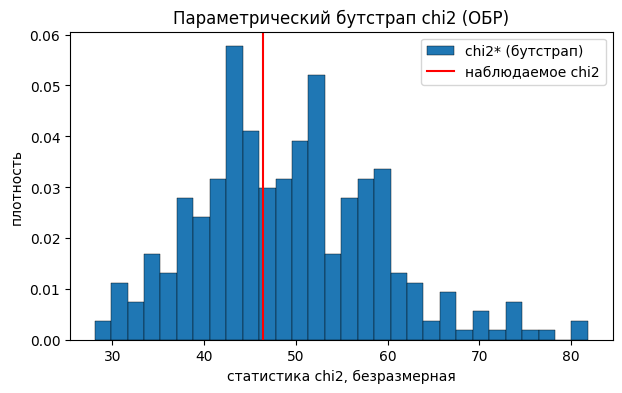

In [25]:
# параметрический бутстрап p-value для chi2: генерация из подогнанной модели, переоценка, chi2
def refit(data):
    if best == "Пуассон":
        lam = data.mean()
        return lambda k: stats.poisson.pmf(k, lam)
    if best == "ОБР":
        n_, p_, _ = fit_nbinom(data, [np.log(n_hat), np.log(p_hat / (1 - p_hat))])
        return lambda k: stats.nbinom.pmf(k, n_, p_)
    mu_, sd_, _ = fit_dnorm(data)
    return lambda k: norm_pmf(k, mu_, sd_)

def simulate(n):
    if best == "Пуассон":
        return rng.poisson(lam_hat, n)
    if best == "ОБР":
        return stats.nbinom.rvs(n_hat, p_hat, size=n, random_state=rng)
    return np.clip(np.round(rng.normal(mu_hat, sd_hat, n)), 0, None).astype(int)

chi2_boot = np.empty(B_BOOT)
for b in range(B_BOOT):
    xb = simulate(N)
    chi2_boot[b] = chi2_gof(xb, refit(xb), models[best]["k"])[0]
p_boot = (1 + np.sum(chi2_boot >= chi2_obs)) / (B_BOOT + 1)
print(f"бутстрап: B = {B_BOOT}, p = {p_boot:.4f}, медиана chi2* = {np.median(chi2_boot):.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(chi2_boot, bins=30, density=True, edgecolor="k", linewidth=0.3, label="chi2* (бутстрап)")
ax.axvline(chi2_obs, color="r", label="наблюдаемое chi2")
ax.set_xlabel("статистика chi2, безразмерная")
ax.set_ylabel("плотность")
ax.set_title(f"Параметрический бутстрап chi2 ({best})")
ax.legend()
plt.show()

In [26]:
# Манн-Уитни: Training против Test
tr = df.loc[df["trianTestLabel"] == "Training", "n_edge"]
te = df.loc[df["trianTestLabel"] == "Test", "n_edge"]
mw = stats.mannwhitneyu(tr, te, alternative="two-sided", method="asymptotic")
mw_effect = mw.statistic / (len(tr) * len(te))
pd.Series({"n Training": len(tr), "n Test": len(te),
           "среднее Training": tr.mean(), "среднее Test": te.mean(),
           "медиана Training": tr.median(), "медиана Test": te.median(),
           "U": mw.statistic, "p-value": mw.pvalue, "U/(n1*n2)": mw_effect})

n Training          1.300500e+04
n Test              2.876000e+03
среднее Training    4.224237e+01
среднее Test        4.018463e+01
медиана Training    4.200000e+01
медиана Test        4.000000e+01
U                   2.151291e+07
p-value             1.158789e-36
U/(n1*n2)           5.751749e-01
dtype: float64

In [27]:
# центр против края по плотностям дефектов
# допущение: числа чипов в зонах в данных нет, чипов в зоне ~ доля площади диска * n_die
frac_c = R_CENTER**2               # r < 0.5
frac_e = 1 - R_EDGE**2             # r > 0.8
rho_c = df["n_center"] / (frac_c * df["n_die"])
rho_e = df["n_edge"] / (frac_e * df["n_die"])
diff = rho_e - rho_c

wx = stats.wilcoxon(diff, alternative="two-sided")
sum_c, sum_e = int(df["n_center"].sum()), int(df["n_edge"].sum())
bt = stats.binomtest(sum_e, sum_e + sum_c, p=frac_e / (frac_e + frac_c))

pd.Series({"доля площади центра": frac_c, "доля площади края": frac_e,
           "средняя плотность центр": rho_c.mean(), "средняя плотность край": rho_e.mean(),
           "медиана разности (край - центр)": diff.median(),
           "доля пластин, где край > центра": (diff > 0).mean(),
           "Wilcoxon W": wx.statistic, "Wilcoxon p": wx.pvalue,
           "binomtest: доля краевых среди (край+центр)": sum_e / (sum_e + sum_c),
           "binomtest: ожидаемая доля": frac_e / (frac_e + frac_c),
           "binomtest p": bt.pvalue})

доля площади центра                           2.500000e-01
доля площади края                             3.600000e-01
средняя плотность центр                       1.780217e-01
средняя плотность край                        2.253968e-01
медиана разности (край - центр)               4.715762e-02
доля пластин, где край > центра               8.180215e-01
Wilcoxon W                                    1.321294e+07
Wilcoxon p                                    0.000000e+00
binomtest: доля краевых среди (край+центр)    6.457936e-01
binomtest: ожидаемая доля                     5.901639e-01
binomtest p                                   0.000000e+00
dtype: float64

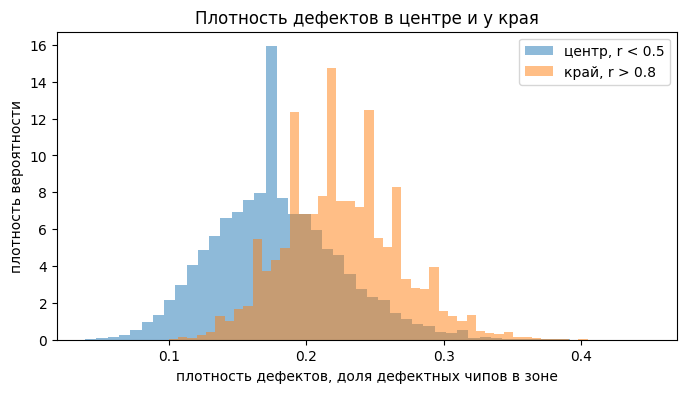

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(rho_c, bins=50, density=True, alpha=0.5, label="центр, r < 0.5")
ax.hist(rho_e, bins=50, density=True, alpha=0.5, label="край, r > 0.8")
ax.set_xlabel("плотность дефектов, доля дефектных чипов в зоне")
ax.set_ylabel("плотность вероятности")
ax.set_title("Плотность дефектов в центре и у края")
ax.legend()
plt.show()

#### Сводная таблица

In [29]:
summary_tab = pd.Series({
    "пластин (n)": N,
    "лотов": df["lotName"].nunique(),
    "dieSize": df["dieSize"].iloc[0],
    "среднее n_edge": m,
    "дисперсия n_edge": v,
    "индекс дисперсии D": v / m,
    "доля нулей": (xv == 0).mean(),
    "асимметрия": stats.skew(xv),
    "эксцесс": stats.kurtosis(xv),
    "внутрилотовая дисперсия": var_within,
    "межлотовая дисперсия": var_between,
    "ICC": icc,
    "Пуассон lambda": lam_hat,
    "ОБР n": n_hat,
    "ОБР p": p_hat,
    "дискр. нормальное mu": mu_hat,
    "дискр. нормальное sigma": sd_hat,
    "AIC Пуассон": aic_table.loc["Пуассон", "AIC"],
    "AIC ОБР": aic_table.loc["ОБР", "AIC"],
    "AIC дискр. нормальное": aic_table.loc["дискр. нормальное", "AIC"],
    "LR Пуассон vs ОБР": lr,
    "p LR": p_lr,
    "Бокс-Кокс lambda": lam_bc,
    f"chi2 согласия ({best})": chi2_obs,
    "df chi2": df_chi2,
    "p chi2": p_chi2,
    "p chi2 бутстрап": p_boot,
    "Манн-Уитни p": mw.pvalue,
    "Манн-Уитни U/(n1*n2)": mw_effect,
    "Wilcoxon p (край vs центр)": wx.pvalue,
    "binomtest p (край vs центр)": bt.pvalue,
}, dtype=object)
summary_tab.map(lambda v: f"{v:.6g}" if isinstance(v, (float, np.floating)) else v).to_frame("значение")

,значение
пластин (n),15881
лотов,715
dieSize,516
среднее n_edge,41.8697
дисперсия n_edge,60.8895
индекс дисперсии D,1.45426
доля нулей,0
асимметрия,0.31441
эксцесс,0.107374
внутрилотовая дисперсия,53.4556


#### Выводы

<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Выводы -->